## Setup

In [1]:
#@title Mount gg drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
#@title Pip install
!pip install -q ultralytics opencv-python matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.4 MB/s eta 0:00:00


In [3]:
#@title Dataset path (.zip)
PROJECT_PATH = "/content/drive/MyDrive/Class Project/Project - Xiangqi detector"

DATASET_PATH_1 = "/content/drive/MyDrive/Class Project/Project - Xiangqi detector/Dataset/Chinese Chess.v1i.yolov8.zip"

In [7]:
#@title Unzip command
!unzip -q "$DATASET_PATH_1" -d /content/raw_dataset_1

## Dataset

**Dataset 1** (`raw_dataset_1`): [Roboflow - Chinese Chess Computer Vision Dataset](https://universe.roboflow.com/viktor-ng/chinese-chess-rtpmq/dataset/1) (object detection task, 200 images, 15 classes)  
-> Dataset 1.1 (`preprocessed_dataset_1`): 14 classes, 8/2/0 train/val/test split  

In [15]:
#@title Dataset path (unzipped)
from pathlib import Path

RAW_DATASET_1_PATH = Path("/content/raw_dataset_1")
PREPROCESSED_DATASET_1_PATH = Path("/content/preprocessed_dataset_1")

In [8]:
#@title Classes

CLASSES = [
    "black_general",      # vua
    "black_advisor",      # si
    "black_elephant",     # tuong
    "black_horse",        # ma
    "black_chariot",      # xe
    "black_cannon",       # phao
    "black_pawn",         # tot

    "red_general",
    "red_advisor",
    "red_elephant",
    "red_horse",
    "red_chariot",
    "red_cannon",
    "red_pawn",
]

In [16]:
#@title Check dataset's data.yaml

from pathlib import Path
import yaml

yaml_path = RAW_DATASET_1_PATH / "data.yaml"

print(yaml_path.read_text())

data = yaml.safe_load(yaml_path.read_text())

print("\nNumber of classes:", data.get("nc"))
print("Classes:", data.get("names"))

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 15
names: ['black-advisor', 'black-cannon', 'black-chariot', 'black-elephant', 'black-general', 'black-horse', 'black-soldier', 'intersection', 'red-advisor', 'red-cannon', 'red-chariot', 'red-elephant', 'red-general', 'red-horse', 'red-soldier']

roboflow:
  workspace: viktor-ng
  project: chinese-chess-rtpmq
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/viktor-ng/chinese-chess-rtpmq/dataset/1

Number of classes: 15
Classes: ['black-advisor', 'black-cannon', 'black-chariot', 'black-elephant', 'black-general', 'black-horse', 'black-soldier', 'intersection', 'red-advisor', 'red-cannon', 'red-chariot', 'red-elephant', 'red-general', 'red-horse', 'red-soldier']


In [17]:
#@title Check dataset's split folders

for split in ["train", "valid", "test"]:
    img_dir = RAW_DATASET_1_PATH / split / "images"
    label_dir = RAW_DATASET_1_PATH / split / "labels"

    if img_dir.exists():
        n_img = len(list(img_dir.glob("*")))
        n_lbl = len(list(label_dir.glob("*.txt")))

        print(f"{split:5s}: {n_img:4d} images | {n_lbl:4d} labels")
    else:
        print(f"{split:5s}: NOT FOUND")

train:  200 images |  200 labels
valid: NOT FOUND
test : NOT FOUND


In [18]:
#@title Prepare dataset 1.1
# Dang co 15 classes (7 do + 7 den + 1 class "intersection" -> loai class intersection)

from pathlib import Path
import shutil
import yaml

(PREPROCESSED_DATASET_1_PATH / "images/train").mkdir(parents=True, exist_ok=True)
(PREPROCESSED_DATASET_1_PATH / "labels/train").mkdir(parents=True, exist_ok=True)

for img_path in (RAW_DATASET_1_PATH / "train/images").glob("*"):
    shutil.copy2(
        img_path,
        PREPROCESSED_DATASET_1_PATH / "images/train" / img_path.name
    )

for label_path in (RAW_DATASET_1_PATH / "train/labels").glob("*.txt"):
    new_lines = []

    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()

            if not parts:
                continue

            cls = int(parts[0])

            # Remove intersection
            if cls == 7:
                continue

            # Remap 8-14 -> 7-13
            if cls > 7:
                cls -= 1

            parts[0] = str(cls)
            new_lines.append(" ".join(parts))

    with open(PREPROCESSED_DATASET_1_PATH / "labels/train" / label_path.name, "w") as f:
        f.write("\n".join(new_lines))


classes = [
    'black-advisor', 'black-cannon', 'black-chariot', 'black-elephant', 'black-general', 'black-horse', 'black-soldier',
    'red-advisor', 'red-cannon', 'red-chariot', 'red-elephant', 'red-general', 'red-horse', 'red-soldier'
]

data_clean = {
    "path": str(PREPROCESSED_DATASET_1_PATH),
    "train": "images/train",
    "val": "images/train",
    "nc": len(classes),
    "names": classes,
}

with open(PREPROCESSED_DATASET_1_PATH / "data.yaml", "w") as f:
    yaml.dump(data_clean, f, sort_keys=False)

print((PREPROCESSED_DATASET_1_PATH / "data.yaml").read_text())

path: /content/preprocessed_dataset_1
train: images/train
val: images/train
nc: 14
names:
- black-advisor
- black-cannon
- black-chariot
- black-elephant
- black-general
- black-horse
- black-soldier
- red-advisor
- red-cannon
- red-chariot
- red-elephant
- red-general
- red-horse
- red-soldier



In [20]:
#@title Prepare dataset 1.1 (2)
# Chi co tap train -> train test split

import yaml
from pathlib import Path
import shutil
import random

# Dataset hien tai
src_images = PREPROCESSED_DATASET_1_PATH / "images/train"
src_labels = PREPROCESSED_DATASET_1_PATH / "labels/train"

# Tao validation
val_images = PREPROCESSED_DATASET_1_PATH / "images/val"
val_labels = PREPROCESSED_DATASET_1_PATH / "labels/val"

val_images.mkdir(parents=True, exist_ok=True)
val_labels.mkdir(parents=True, exist_ok=True)

images = list(src_images.glob("*"))
random.seed(42)
random.shuffle(images)

n_val = int(len(images) * 0.2)
val_set = images[:n_val]

for img_path in val_set:
    label_path = src_labels / f"{img_path.stem}.txt"

    shutil.move(
        str(img_path),
        str(val_images / img_path.name)
    )

    shutil.move(
        str(label_path),
        str(val_labels / label_path.name)
    )

print(f"Train: {len(list(src_images.glob('*')))}")
print(f"Val:   {len(list(val_images.glob('*')))}")

yaml_path = PREPROCESSED_DATASET_1_PATH / "data.yaml"

data = yaml.safe_load(yaml_path.read_text())

data["train"] = "images/train"
data["val"] = "images/val"
data["nc"] = 14

with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print(yaml_path.read_text())

Train: 160
Val:   40
path: /content/preprocessed_dataset_1
train: images/train
val: images/val
nc: 14
names:
- black-advisor
- black-cannon
- black-chariot
- black-elephant
- black-general
- black-horse
- black-soldier
- red-advisor
- red-cannon
- red-chariot
- red-elephant
- red-general
- red-horse
- red-soldier



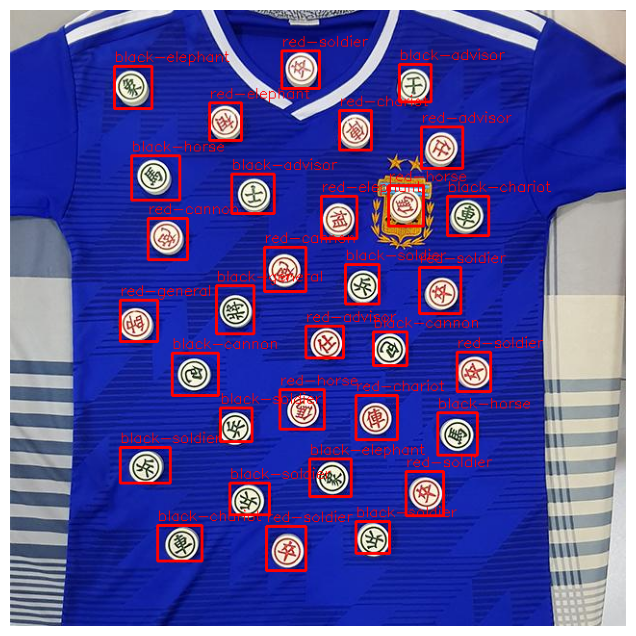

In [21]:
#@title Visualize a random image

import cv2
import matplotlib.pyplot as plt
import random

img_path = random.choice(
    list((PREPROCESSED_DATASET_1_PATH / "images/val").glob("*"))
)

label_path = PREPROCESSED_DATASET_1_PATH / "labels/val" / f"{img_path.stem}.txt"

img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

with open(label_path) as f:
    for line in f:
        cls, xc, yc, bw, bh = map(float, line.split())

        cls = int(cls)

        xc *= w
        yc *= h
        bw *= w
        bh *= h

        x1 = int(xc - bw / 2)
        y1 = int(yc - bh / 2)
        x2 = int(xc + bw / 2)
        y2 = int(yc + bh / 2)

        cv2.rectangle(
            img,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        cv2.putText(
            img,
            data["names"][cls],
            (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            1
        )

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off");

## Model

In [23]:
#@title Load pretrained model

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

In [24]:
#@title Training

SEED = 42
DATASET_NAME = "preprocessed_dataset_1"       #@param { "type": "string" }
RUN_NAME = "xiangqi_yolov8n_preprocessed_dataset_1"       #@param { "type": "string" }

EPOCHS = 30

results = model.train(
    data=f"/content/{DATASET_NAME}/data.yaml",

    epochs=EPOCHS,
    imgsz=640,
    batch=16,
    device=0,

    project="/content/runs",
    name=RUN_NAME,

    pretrained=True,
    seed=SEED
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/preprocessed_dataset_1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=xiangqi_yolov8n_preprocessed_dataset_1, nbs=64,

In [25]:
#@title Validating

metrics = model.val(
    data=f"/content/{DATASET_NAME}/data.yaml",
    split="val"
)

print(metrics)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,135,866 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2092.8±600.5 MB/s, size: 66.2 KB)
val: Scanning /content/preprocessed_dataset_1/labels/val.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 14.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.1s
                   all         40       1223       0.45      0.721      0.572      0.397
         black-advisor         39         77      0.793      0.797      0.909      0.662
          black-cannon         38         74      0.624      0.932      0.905      0.614
         black-chariot         39         77      0.263      0.922      0.307      0.225
        black-elephant         39         79      0.381      0.722      0.554      0.381
         black-general         38       

In [26]:
#@title Test prediction

results = model.predict(
    source=f"/content/{DATASET_NAME}/images/val",
    imgsz=640,
    conf=0.25,
    save=True
)


image 1/40 /content/preprocessed_dataset_1/images/val/06b01d59-Untitled-30_jpg.rf.25d92b5cf344baf730a0d647f40db497.jpg: 640x640 1 black-advisor, 2 black-cannons, 2 black-chariots, 2 black-elephants, 9 black-horses, 5 black-soldiers, 12.5ms
image 2/40 /content/preprocessed_dataset_1/images/val/072cfa6a-Untitled-24_jpg.rf.ac566da623743ac9c023cfb44a5a5f52.jpg: 640x640 2 black-advisors, 1 black-cannon, 4 black-chariots, 4 black-elephants, 5 black-horses, 2 black-soldiers, 2 red-advisors, 1 red-cannon, 4 red-chariots, 2 red-elephants, 5 red-horses, 4 red-soldiers, 12.5ms
image 3/40 /content/preprocessed_dataset_1/images/val/09025cc0-Untitled-160_jpg.rf.4a3a16652b18e8d88454750b05aba1dd.jpg: 640x640 2 black-advisors, 3 black-cannons, 6 black-chariots, 2 black-generals, 5 black-horses, 6 black-soldiers, 1 red-advisor, 8 red-chariots, 2 red-horses, 5 red-soldiers, 12.5ms
image 4/40 /content/preprocessed_dataset_1/images/val/0a426c3e-Untitled-146_jpg.rf.231702240f0fbebc95babead99defc0b.jpg: 640

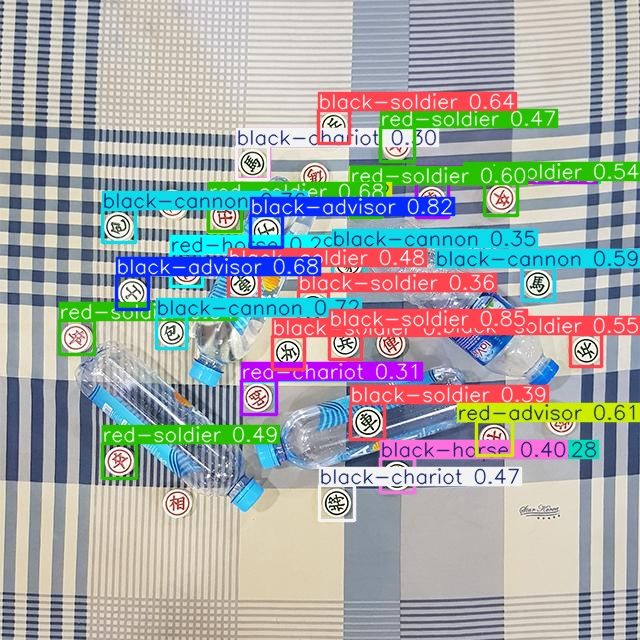

In [27]:
#@title Visualize prediction

from pathlib import Path
from IPython.display import display
from PIL import Image

pred_dir = Path("/content/runs/detect/predict")

img = next(pred_dir.glob("*"))
display(Image.open(img))

In [28]:
#@title Save model
cp_src = f"/content/runs/{RUN_NAME}/weights/best.pt"
cp_dst = f"/content/drive/MyDrive/Class Project/Project - Xiangqi detector/Models/{RUN_NAME}.pt"

!cp "$cp_src" "$cp_dst"

In [29]:
#@title Load best model

from ultralytics import YOLO

MODEL_PATH = f"/content/runs/{RUN_NAME}/weights/best.pt"

model = YOLO(MODEL_PATH)
print("Model loaded:", MODEL_PATH)

Model loaded: /content/runs/xiangqi_yolov8n_preprocessed_dataset_1/weights/best.pt
